# Applying aPMV setpoints

## Introduction

This notebook demonstrates how to use the `accim` library to implement **Adaptive Predicted Mean Vote (aPMV)** control strategies in EnergyPlus models. 

The aPMV model extends the standard Fanger PMV model by introducing an adaptive coefficient ($\lambda$). This coefficient accounts for the psychological, physiological, and behavioral adaptations of occupants in naturally ventilated or mixed-mode buildings. By dynamically adjusting HVAC setpoints based on aPMV, we can often achieve thermal comfort with lower energy consumption compared to static setpoints.

## Objectives of this Notebook

1.  **Setup:** Load a residential EnergyPlus model and prepare it for simulation.
2.  **Inspect:** Identify the valid control targets (Zones/Spaces) within the model.
3.  **Base Case (PMV):** Simulate the building using standard PMV setpoints ($\lambda = 0$).
4.  **Adaptive Case (aPMV):** Simulate the building using aPMV setpoints with custom coefficients for specific zones.
5.  **Compare:** Analyze the differences in setpoints and comfort between the two strategies.

## 1. Setup and Imports

We import the necessary libraries for simulation (`besos`, `accim`) and data analysis (`pandas`, `matplotlib`, `seaborn`).

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from besos import eppy_funcs as ef
from besos import eplus_funcs as ep

# Import the accim module
import accim.sim.apmv_setpoints as apmv

# Visualization setup
plt.rcParams['figure.figsize'] = [14, 6]
sns.set_style("whitegrid")

# Define file paths
idf_filename = "TestModel_TestResidentialUnit.idf"
epw_filename = 'Seville.epw'

# Check files
if not os.path.exists(idf_filename):
    print(f"⚠️ Warning: {idf_filename} not found.")
else:
    print(f"✅ Model found: {idf_filename}")

✅ Model found: TestModel_TestResidentialUnit.idf


## 2. Loading the Model

We use BESOS to load the IDF file. This creates a building object that we can manipulate in memory.

In [2]:
# Load initial instance for inspection
building = ef.get_building(idf_filename)

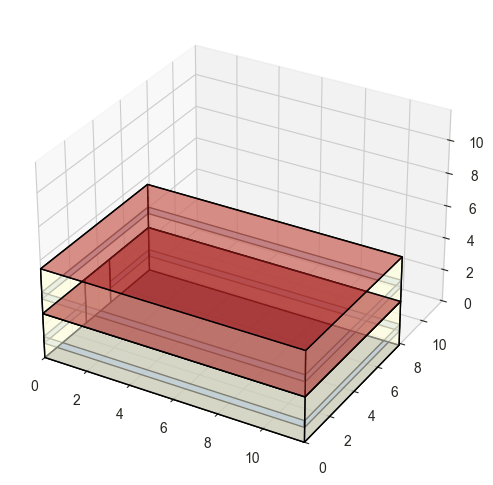

In [3]:
# Let's visualise the geometry of the model with geomeppy
from geomeppy import IDF

# geomeppy needs the IDD file of the EnergyPlus version of the IDF (25.1)
IDF.setiddname(r"C:\EnergyPlusV25-1-0\Energy+.idd")
idf_geo = IDF(idf_filename)

# In a Jupyter notebook, the 3D view is shown below the cell; in a script, it opens in a separate window.
idf_geo.view_model()

## 3. Model Preparation (Occupancy and PMV Inputs)

To ensure the adaptive control logic is active and visible throughout the simulation period, we need to ensure the zones are occupied. The `accim` library provides a helper function to force occupancy schedules to 'Always On'.

The PMV also depends on the activity, clothing, air velocity and work efficiency of the occupants, which are defined in the `People` objects. The function `set_pmv_input_parameters` changes them; we will use the same values in both cases (100 W/person, 0.1 m/s and a work efficiency of 0, instead of the 0.3 m/s and 0.3 of the model), so the only difference between the cases is the adaptive coefficient. The clothing insulation of the model (1 clo) is kept.

**Note:** `apply_apmv_setpoints` turns the thermostats of the zones (`ZoneControl:Thermostat`) into thermal comfort thermostats with Fanger setpoints, and creates them if a zone has none. The model needs an HVAC system able to heat and cool the zones; this one has a VRF system.

In [4]:
# Set Occupancy to 'Always On' to ensure continuous control
print("--- Setting Occupancy ---")
apmv.set_zones_always_occupied(building=building, verbose_mode=True)

# PMV inputs used in both cases: activity level (W/person), air velocity (m/s) and work efficiency
pmv_inputs = {'activity_level': 100, 'air_velocity': 0.1, 'work_efficiency': 0.0}

--- Setting Occupancy ---
Added Schedule: On
Updated all People objects to use schedule 'On'.


## 4. Implementing aPMV setpoints

The core function of this module is `apply_apmv_setpoints`. This function injects Energy Management System (EMS) code into the IDF to calculate setpoints dynamically.

### Key Parameters:

*   `adap_coeff_cooling` / `adap_coeff_heating`: The adaptive coefficient ($\lambda$) in the cooling and heating seasons.
    *   If $\lambda = 0$, aPMV equals PMV, so the logic mimics standard Fanger PMV setpoints.
    *   A positive $\lambda$ (usually in the cooling season) allows warmer conditions, and a negative $\lambda$ (usually in the heating season) allows cooler conditions, for the same aPMV setpoints.
    *   Can be a single `float` (global) or a `dict` (per zone).
*   `pmv_cooling_sp` / `pmv_heating_sp`: The target setpoints on the **aPMV** scale (e.g., +0.5 for cooling, -0.5 for heating). The thermostat controls the Fanger PMV, so the EMS program sends it the PMV whose aPMV is the setpoint: since $aPMV = PMV / (1 + \lambda \cdot PMV)$, that is $PMV = aPMV / (1 - \lambda \cdot aPMV)$.
*   `tolerance_...`: Additional deadbands applied to the setpoints, on the aPMV scale.
    *   **Default values:** `-0.1` for the cooling setpoint and `0.1` for the heating setpoint.
    *   **How it works:** The tolerance tightens the setpoint range to create a safety margin. For example, if you specify a `pmv_cooling_sp` of **0.5**, the effective aPMV setpoint used in the simulation will be **0.4** ($0.5 - 0.1$). Similarly, for a `pmv_heating_sp` of **-0.5**, the effective aPMV setpoint becomes **-0.4** ($-0.5 + 0.1$).
    *   **Purpose:** This ensures that all simulation hours remain strictly within the desired limits, preventing situations where setpoints are exceeded by small fractions (tenths or hundredths).

### Inspecting Targets

Before applying the logic, we must know **where** to apply it. The function `get_available_target_names` scans the model for People objects and returns the valid keys (Zone or Space names) to use in our configuration.

In [5]:
# Identify valid targets in the model
target_names = apmv.get_available_target_names(building=building)

print(f"Found {len(target_names)} targets:")
for t in target_names:
    print(f" - {t}")

Found 2 targets:
 - Floor_1 Residential Living Occupants
 - Floor_2 Residential Living Occupants


### Generating an Input Template

Most parameters in `accim` (such as adaptive coefficients $\lambda$, setpoints, or tolerances) can be configured **independently for each zone**.

To do this, instead of passing a single number (which applies globally), you pass a **dictionary** following the pattern `{'Target Name': value}`.

If you are unsure of the exact keys to use, the function `get_input_template_dictionary` generates a blank dictionary containing all valid target keys found in your model.

In [6]:
# Generate a template dictionary
template = apmv.get_input_template_dictionary(building=building)

print("Template dictionary structure:")
print(template)

Template dictionary structure:
{'Floor_1 Residential Living Occupants': 'replace-me-with-float-value', 'Floor_2 Residential Living Occupants': 'replace-me-with-float-value'}


### 4.1 Base case

#### 4.1.1 Implementing PMV setpoints

In this section, we generate the **Base Case**. We will use the `apply_apmv_setpoints` function, but we will set the adaptive coefficients (`adap_coeff_cooling` and `adap_coeff_heating`) to **0**.

Mathematically, if $\lambda = 0$, then $aPMV = PMV$. This effectively simulates a standard Fanger PMV control strategy.

In [7]:
# 1. Reload model to ensure a clean state
building_base = ef.get_building(idf_filename)
apmv.set_zones_always_occupied(building_base, verbose_mode=False)
apmv.set_pmv_input_parameters(building=building_base, **pmv_inputs)

Set Activity for 'Residential Living Occupants': 100 W/person
Set Air Velocity for 'Residential Living Occupants': 0.1 m/s
Set Work Efficiency for 'Residential Living Occupants': 0.0


In [8]:
# 2. Apply PMV logic (Lambda = 0)
print("Applying Base Case (PMV) logic...")
building_base = apmv.apply_apmv_setpoints(
    building=building_base,
    adap_coeff_cooling=0,  # Zero means standard PMV
    adap_coeff_heating=0,  # Zero means standard PMV
    pmv_cooling_sp=0.5,
    pmv_heating_sp=-0.5,
    cooling_season_start='01/05',
    cooling_season_end='30/09',
    verbose_mode=False
)

Applying Base Case (PMV) logic...


accim\sim\apmv_setpoints.py:1027: UserWarning: Output:Variable already exists for 'Zone Operative Temperature' (Hourly). Skipping.
  warnings.warn(f"Output:Variable already exists for '{item}' ({freq_cap}). Skipping.")
accim\sim\apmv_setpoints.py:1027: UserWarning: Output:Variable already exists for 'Zone Thermal Comfort Fanger Model PMV' (Hourly). Skipping.
  warnings.warn(f"Output:Variable already exists for '{item}' ({freq_cap}). Skipping.")


#### 4.1.2 PMV setpoints simulation

We run the simulation for the base case and store the results.

In [9]:
out_dir_base = 'sim_results_base'
print(f"Running Base Case simulation in {out_dir_base}...")

ep.run_building(
    building=building_base,
    out_dir=out_dir_base,
    epw=epw_filename
)
print("Base simulation finished.")

Running Base Case simulation in sim_results_base...
Running EnergyPlus with stdout output suppressed...
Base simulation finished.


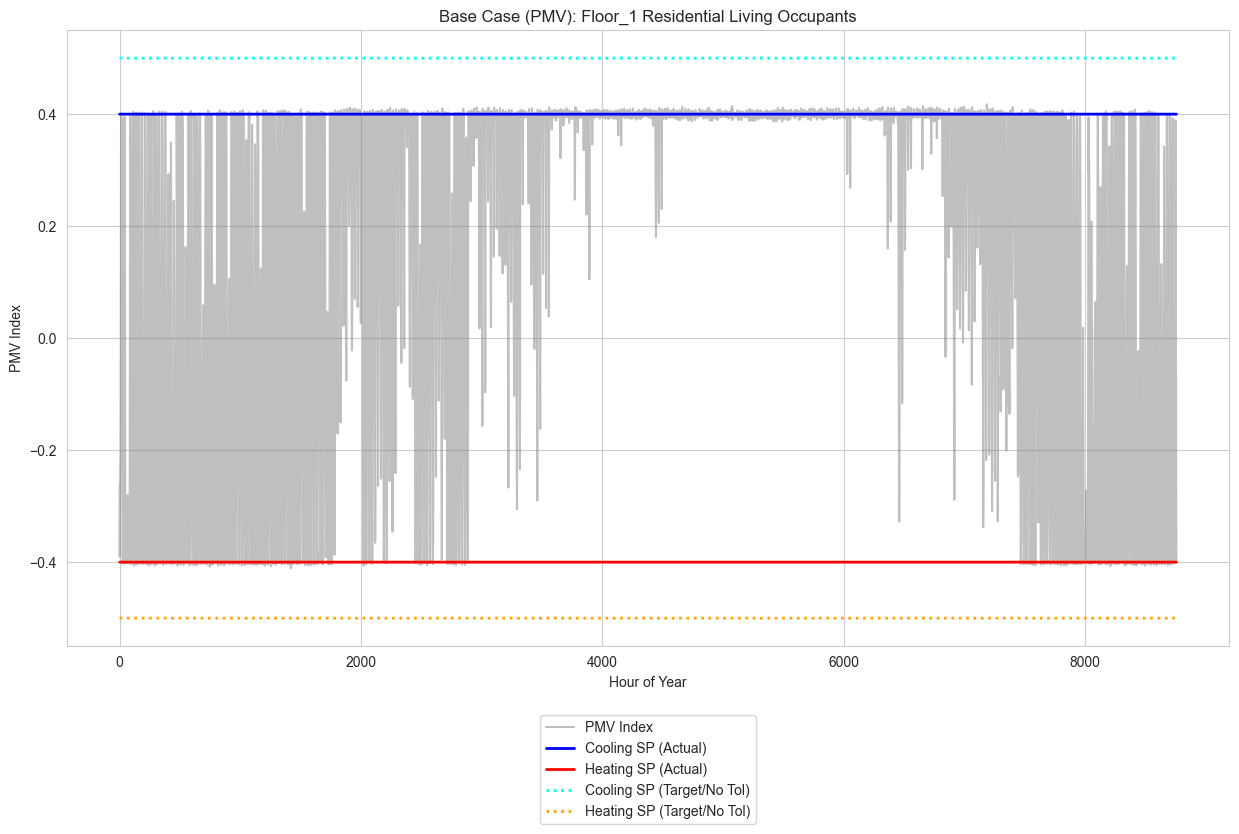

In [10]:
# Load Base Results
df_base = pd.read_csv(os.path.join(out_dir_base, 'eplusout.csv'))
df_base['Hour'] = df_base.index

# Visualize Zone 1 (Example)
target_zone = target_names[0].replace(" ", "_").replace(":", "_") # Sanitize name for column search

plt.figure(figsize=(15, 8))

# Filter for summer period (approx hours 3600 to 4300)
# start_h = 3600
# end_h = 4300
# subset = df_base.iloc[start_h:end_h]
subset = df_base

try:
    # 1. Identify Columns
    # Actual PMV Value
    col_pmv = [c for c in df_base.columns if 'EMS:aPMV' in c and target_zone in c and 'Setpoint' not in c][0]

    # Actual Setpoints (With Tolerance applied)
    col_cool = [c for c in df_base.columns if 'EMS:aPMV Cooling Setpoint' in c and target_zone in c and 'No Tolerance' not in c][0]
    col_heat = [c for c in df_base.columns if 'EMS:aPMV Heating Setpoint' in c and target_zone in c and 'No Tolerance' not in c][0]

    # Target Setpoints (No Tolerance - The theoretical limit)
    col_cool_no_tol = [c for c in df_base.columns if 'EMS:aPMV Cooling Setpoint No Tolerance' in c and target_zone in c][0]
    col_heat_no_tol = [c for c in df_base.columns if 'EMS:aPMV Heating Setpoint No Tolerance' in c and target_zone in c][0]

    # 2. Plotting
    # Plot PMV Index
    sns.lineplot(x=subset.index, y=subset[col_pmv], label='PMV Index', color='gray', alpha=0.5)

    # Plot Actual Setpoints (Solid lines)
    sns.lineplot(x=subset.index, y=subset[col_cool], label='Cooling SP (Actual)', color='blue', linewidth=2)
    sns.lineplot(x=subset.index, y=subset[col_heat], label='Heating SP (Actual)', color='red', linewidth=2)

    # Plot Theoretical Setpoints (Dotted lines)
    sns.lineplot(x=subset.index, y=subset[col_cool_no_tol], label='Cooling SP (Target/No Tol)', color='cyan', linestyle=':', linewidth=2)
    sns.lineplot(x=subset.index, y=subset[col_heat_no_tol], label='Heating SP (Target/No Tol)', color='orange', linestyle=':', linewidth=2)

    plt.title(f"Base Case (PMV): {target_names[0]}")
    plt.ylabel("PMV Index")
    plt.xlabel("Hour of Year")
    plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.3))
    plt.show()
    plt.show()

except IndexError:
    print("Could not find output columns. Check simulation results.")

### 4.2 aPMV setpoints implemented case

#### 4.2.1 Implementing aPMV setpoints

Now we generate the **Adaptive Case**. We will define specific adaptive coefficients for our zones.

*   **Floor_1 Residential Living Occupants:** High adaptation ($\lambda = 0.4$).
*   **Floor_2 Residential Living Occupants:** Low adaptation ($\lambda = 0.1$).

These coefficients apply in the cooling season; in the heating season, both zones use $\lambda = -0.1$ (`adap_coeff_heating`).

In [11]:
# 1. Reload model fresh
building_apmv = ef.get_building(idf_filename)
apmv.set_zones_always_occupied(building_apmv, verbose_mode=False)

In [12]:
custom_coeffs = apmv.get_input_template_dictionary(building=building_apmv)
print(custom_coeffs)

{'Floor_1 Residential Living Occupants': 'replace-me-with-float-value', 'Floor_2 Residential Living Occupants': 'replace-me-with-float-value'}


In [13]:
for k, v in custom_coeffs.items():
    if 'Floor_1 Residential Living Occupants' == k:
        custom_coeffs[k] = 0.4
    elif 'Floor_2 Residential Living Occupants' == k:
        custom_coeffs[k] = 0.1

print(custom_coeffs)

{'Floor_1 Residential Living Occupants': 0.4, 'Floor_2 Residential Living Occupants': 0.1}


In [14]:
# 2. Same PMV inputs as in the base case
apmv.set_pmv_input_parameters(building=building_apmv, **pmv_inputs)

Set Activity for 'Residential Living Occupants': 100 W/person
Set Air Velocity for 'Residential Living Occupants': 0.1 m/s
Set Work Efficiency for 'Residential Living Occupants': 0.0


In [15]:
# 3. Apply aPMV logic
print("Applying Adaptive Case (aPMV) logic...")
building_apmv = apmv.apply_apmv_setpoints(
    building=building_apmv,
    adap_coeff_cooling=custom_coeffs,
    adap_coeff_heating=-0.1, # Global value for heating
    pmv_cooling_sp=0.5,
    pmv_heating_sp=-0.5,
    cooling_season_start='01/05',
    cooling_season_end='30/09',
    verbose_mode=False,
    outputs_freq=['hourly']
)

Applying Adaptive Case (aPMV) logic...


accim\sim\apmv_setpoints.py:1027: UserWarning: Output:Variable already exists for 'Zone Operative Temperature' (Hourly). Skipping.
  warnings.warn(f"Output:Variable already exists for '{item}' ({freq_cap}). Skipping.")
accim\sim\apmv_setpoints.py:1027: UserWarning: Output:Variable already exists for 'Zone Thermal Comfort Fanger Model PMV' (Hourly). Skipping.
  warnings.warn(f"Output:Variable already exists for '{item}' ({freq_cap}). Skipping.")


In [16]:
# Verify the EMS Program generation
# We search for the 'apply_aPMV' program corresponding to the first target zone to inspect the logic

# 1. Construct the expected program name (accim sanitizes spaces to underscores)
target_sanitized = target_names[0].replace(" ", "_").replace(":", "_")
prog_name_search = f"apply_aPMV_{target_sanitized}"

# 2. Find the object in the IDF
programs = [p for p in building_apmv.idfobjects['EnergyManagementSystem:Program'] if prog_name_search in p.Name]

# 3. Display the result
if programs:
    print(f"--- EMS Program found for {target_names[0]} ---")
    print(programs[0])
else:
    print(f"EMS Program '{prog_name_search}' not found.")

--- EMS Program found for Floor_1 Residential Living Occupants ---

ENERGYMANAGEMENTSYSTEM:PROGRAM,
    apply_aPMV_Floor_1_Residential_Living_Occupants,    !- Name
    if CoolingSeason == 1,    !- Program Line 1
    set adap_coeff_Floor_1_Residential_Living_Occupants = adap_coeff_cooling_Floor_1_Residential_Living_Occupants,    !- Program Line 2
    set tolerance_cooling_sp_Floor_1_Residential_Living_Occupants = tolerance_cooling_sp_cooling_season_Floor_1_Residential_Living_Occupants,    !- Program Line 3
    set tolerance_heating_sp_Floor_1_Residential_Living_Occupants = tolerance_heating_sp_cooling_season_Floor_1_Residential_Living_Occupants,    !- Program Line 4
    elseif CoolingSeason == 0,    !- Program Line 5
    set adap_coeff_Floor_1_Residential_Living_Occupants = adap_coeff_heating_Floor_1_Residential_Living_Occupants,    !- Program Line 6
    set tolerance_cooling_sp_Floor_1_Residential_Living_Occupants = tolerance_cooling_sp_heating_season_Floor_1_Residential_Living_Occupan

#### 4.2.2 aPMV setpoints simulation

We run the simulation for the adaptive case.

In [17]:
out_dir_apmv = 'sim_results_apmv'
print(f"Running Adaptive Case simulation in {out_dir_apmv}...")

ep.run_building(
    building=building_apmv,
    out_dir=out_dir_apmv,
    epw=epw_filename
)
print("Adaptive simulation finished.")

Running Adaptive Case simulation in sim_results_apmv...
Running EnergyPlus with stdout output suppressed...
Adaptive simulation finished.


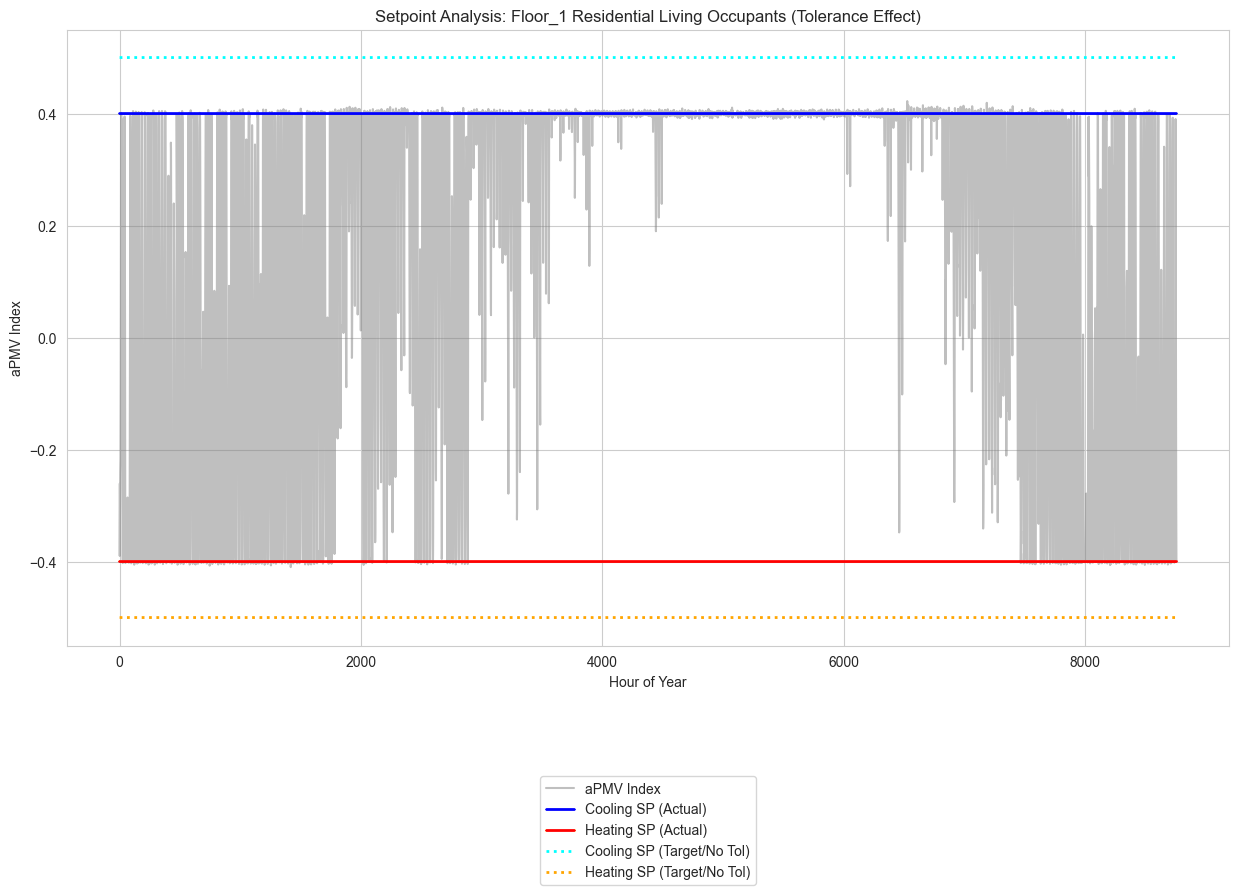

In [18]:
# Load aPMV Results
df_apmv = pd.read_csv(os.path.join(out_dir_apmv, 'eplusout.csv'))
df_apmv['Hour'] = df_apmv.index

# Visualize Zone 1 (Example)
target_zone = target_names[0].replace(" ", "_").replace(":", "_") # Sanitize name for column search
plt.figure(figsize=(15, 8))

# Filter for summer period (approx hours 3600 to 4300)
# start_h = 3600
# end_h = 4300
# subset = df_apmv.iloc[start_h:end_h]
subset = df_apmv


try:
    # 1. Identify Columns
    # Actual aPMV Value
    col_apmv = [c for c in df_apmv.columns if 'EMS:aPMV' in c and target_zone in c and 'Setpoint' not in c][0]
    # Actual Setpoints (With Tolerance applied)
    col_cool = [c for c in df_apmv.columns if 'EMS:aPMV Cooling Setpoint' in c and target_zone in c and 'No Tolerance' not in c][0]
    col_heat = [c for c in df_apmv.columns if 'EMS:aPMV Heating Setpoint' in c and target_zone in c and 'No Tolerance' not in c][0]

    # Target Setpoints (No Tolerance - The theoretical limit)
    col_cool_no_tol = [c for c in df_apmv.columns if 'EMS:aPMV Cooling Setpoint No Tolerance' in c and target_zone in c][0]
    col_heat_no_tol = [c for c in df_apmv.columns if 'EMS:aPMV Heating Setpoint No Tolerance' in c and target_zone in c][0]

    # 2. Plotting
    # Plot PMV Index
    sns.lineplot(x=subset.index, y=subset[col_apmv], label='aPMV Index', color='gray', alpha=0.5)
    # Plot Actual Setpoints (Solid lines)
    sns.lineplot(x=subset.index, y=subset[col_cool], label='Cooling SP (Actual)', color='blue', linewidth=2)
    sns.lineplot(x=subset.index, y=subset[col_heat], label='Heating SP (Actual)', color='red', linewidth=2)

    # Plot Theoretical Setpoints (Dotted lines)
    sns.lineplot(x=subset.index, y=subset[col_cool_no_tol], label='Cooling SP (Target/No Tol)', color='cyan', linestyle=':', linewidth=2)
    sns.lineplot(x=subset.index, y=subset[col_heat_no_tol], label='Heating SP (Target/No Tol)', color='orange', linestyle=':', linewidth=2)

    plt.title(f"Setpoint Analysis: {target_names[0]} (Tolerance Effect)")
    plt.ylabel("aPMV Index")
    plt.xlabel("Hour of Year")
    plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.4))
    plt.show()

except IndexError:
    print("Error: Could not find matching columns for comparison.")

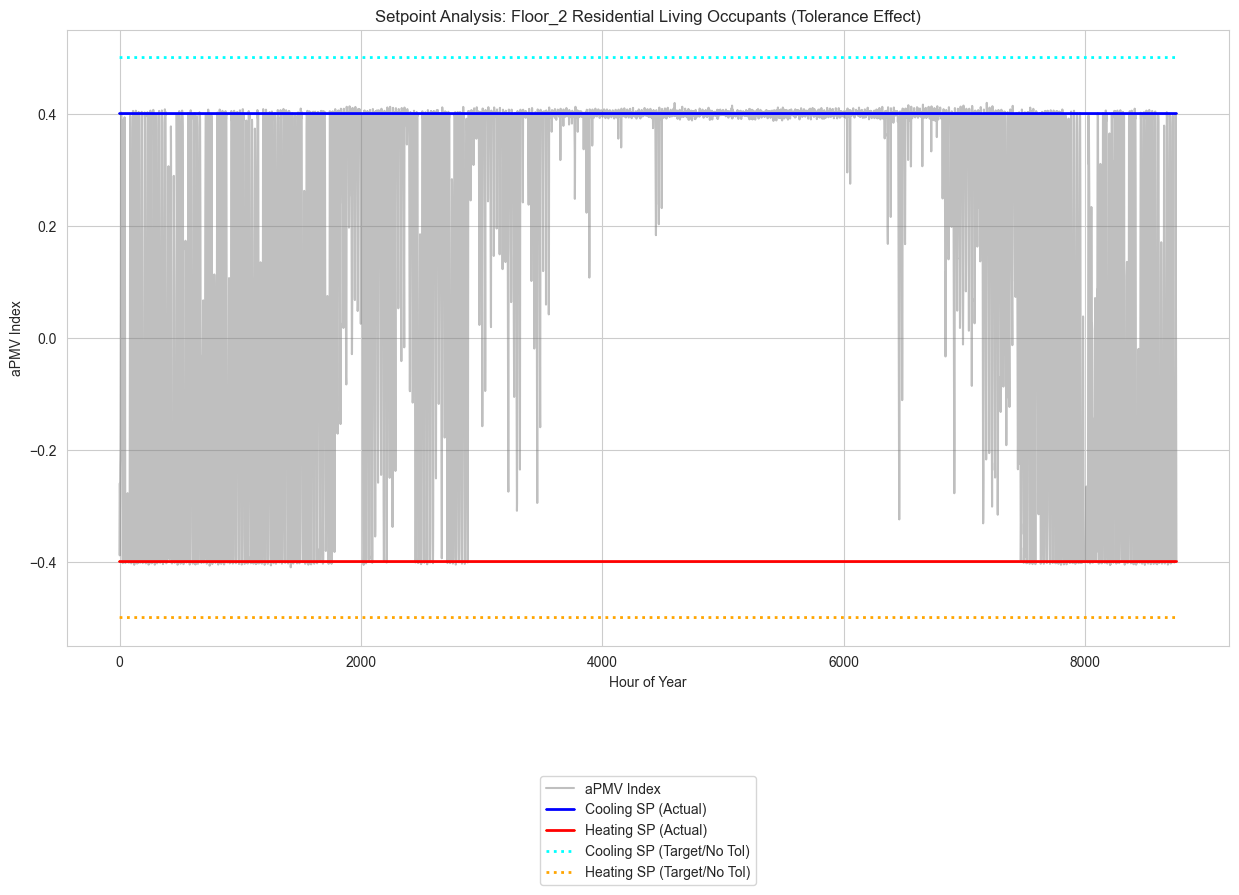

In [19]:
# Load aPMV Results
df_apmv = pd.read_csv(os.path.join(out_dir_apmv, 'eplusout.csv'))
df_apmv['Hour'] = df_apmv.index

# Visualize Zone 2
target_zone = target_names[1].replace(" ", "_").replace(":", "_") # Sanitize name for column search
plt.figure(figsize=(15, 8))

# Filter for summer period (approx hours 3600 to 4300)
# start_h = 3600
# end_h = 4300
# subset = df_apmv.iloc[start_h:end_h]
subset = df_apmv


try:
    # 1. Identify Columns
    # Actual aPMV Value
    col_apmv = [c for c in df_apmv.columns if 'EMS:aPMV' in c and target_zone in c and 'Setpoint' not in c][0]
    # Actual Setpoints (With Tolerance applied)
    col_cool = [c for c in df_apmv.columns if 'EMS:aPMV Cooling Setpoint' in c and target_zone in c and 'No Tolerance' not in c][0]
    col_heat = [c for c in df_apmv.columns if 'EMS:aPMV Heating Setpoint' in c and target_zone in c and 'No Tolerance' not in c][0]

    # Target Setpoints (No Tolerance - The theoretical limit)
    col_cool_no_tol = [c for c in df_apmv.columns if 'EMS:aPMV Cooling Setpoint No Tolerance' in c and target_zone in c][0]
    col_heat_no_tol = [c for c in df_apmv.columns if 'EMS:aPMV Heating Setpoint No Tolerance' in c and target_zone in c][0]

    # 2. Plotting
    # Plot PMV Index
    sns.lineplot(x=subset.index, y=subset[col_apmv], label='aPMV Index', color='gray', alpha=0.5)
    # Plot Actual Setpoints (Solid lines)
    sns.lineplot(x=subset.index, y=subset[col_cool], label='Cooling SP (Actual)', color='blue', linewidth=2)
    sns.lineplot(x=subset.index, y=subset[col_heat], label='Heating SP (Actual)', color='red', linewidth=2)

    # Plot Theoretical Setpoints (Dotted lines)
    sns.lineplot(x=subset.index, y=subset[col_cool_no_tol], label='Cooling SP (Target/No Tol)', color='cyan', linestyle=':', linewidth=2)
    sns.lineplot(x=subset.index, y=subset[col_heat_no_tol], label='Heating SP (Target/No Tol)', color='orange', linestyle=':', linewidth=2)

    plt.title(f"Setpoint Analysis: {target_names[1]} (Tolerance Effect)")
    plt.ylabel("aPMV Index")
    plt.xlabel("Hour of Year")
    plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.4))
    plt.show()

except IndexError:
    print("Error: Could not find matching columns for comparison.")

## 5. Results Comparison: Comfort vs. Energy

In this final section, we compare comfort and energy in both simulations, for the first target zone (Floor_1).

Since `pmv_cooling_sp` and `pmv_heating_sp` are targets on the aPMV scale, both strategies keep their own comfort index within the same setpoints (-0.5 and 0.5, or -0.4 and 0.4 with the tolerances), as the figures above show. The difference appears on the PMV scale: the thermostat of the Adaptive Case receives $PMV = aPMV / (1 - \lambda \cdot aPMV)$. In Floor_1, with $\lambda = 0.4$ in the cooling season, aPMV setpoints of -0.5 and 0.5 become PMV setpoints of -0.417 and 0.625; with $\lambda = -0.1$ in the heating season, they become -0.526 and 0.476. So, compared with the Base Case, the comfort band moves towards warmer conditions in the cooling season and towards cooler conditions in the heating season.

We generate a **Joint Plot** that combines:
1.  **Scatter Plot:** the Fanger PMV of the zone against the hourly HVAC electricity, for both cases.
2.  **Distributions:** density curves on the margins.
3.  **Setpoint Lines:** the PMV setpoints (without tolerance) of the Base Case, and those of the Adaptive Case in each season.

Plotting: FLOOR_1 RESIDENTIAL LIVING OCCUPANTS:Zone Thermal Comfort Fanger Model PMV vs Electricity:HVAC

Annual HVAC electricity (kWh):
Source
PMV (base case)         10212.2
aPMV (adaptive case)    10035.4
Adaptive case, cooling season (lambda = 0.4): PMV setpoints -0.417 and 0.625
Adaptive case, heating season (lambda = -0.1): PMV setpoints -0.526 and 0.476


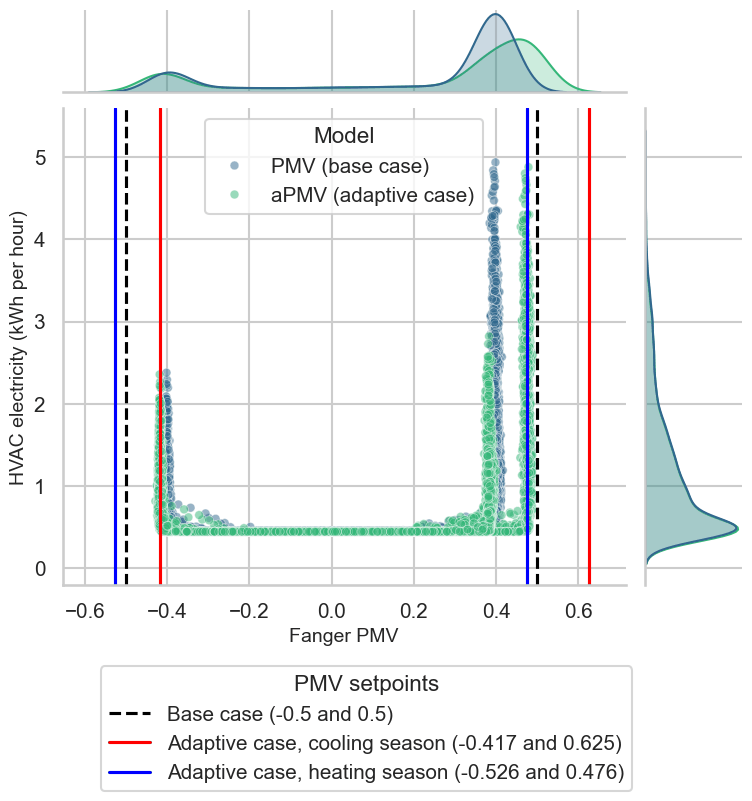

In [20]:
import os
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Silence the FutureWarnings of seaborn about pandas
warnings.simplefilter(action='ignore', category=FutureWarning)

# =============================================================================
# 1. DATA LOADING AND PREPARATION
# =============================================================================

# Paths to the results of sections 4.1.2 and 4.2.2
path_pmv = os.path.join('sim_results_base', 'eplusout.csv')
path_apmv = os.path.join('sim_results_apmv', 'eplusout.csv')

# Adaptive coefficients of the first target zone in section 4.2
lambda_cooling = custom_coeffs[target_names[0]]  # 0.4
lambda_heating = -0.1

try:
    df_pmv = pd.read_csv(path_pmv)
    df_pmv['Source'] = 'PMV (base case)'
    df_apmv = pd.read_csv(path_apmv)
    df_apmv['Source'] = 'aPMV (adaptive case)'
    df = pd.concat([df_pmv, df_apmv], ignore_index=True)

    # Remove the units and the frequency from the column names
    df.columns = df.columns.str.replace(r'\s*\[.*?\]\(Hourly\)?', '', regex=True).str.strip()

    # Fanger PMV of the first target zone (the People object of that zone)
    pmv_cols = [c for c in df.columns if 'Fanger Model PMV' in c and target_names[0].upper() in c.upper()]
    if not pmv_cols:
        raise KeyError(f"PMV column not found for {target_names[0]}")
    pmv_col = pmv_cols[0]

    # HVAC electricity: the meter Electricity:HVAC is in J, so it is converted to kWh
    elec_cols = [c for c in df.columns if 'Electricity:HVAC' in c]
    if not elec_cols:
        raise KeyError("Electricity:HVAC column not found")
    df['HVAC Electricity'] = df[elec_cols[0]] / 3.6e6

    print(f"Plotting: {pmv_col} vs {elec_cols[0]}")
    print('\nAnnual HVAC electricity (kWh):')
    print(df.groupby('Source')['HVAC Electricity'].sum().round(1).to_string())

except FileNotFoundError:
    print("Error: Result files not found. Ensure you have run the simulations (Steps 4.1.2 and 4.2.2).")
except KeyError as e:
    print(f"Data Error: {e}")

else:
    # =============================================================================
    # 2. FIGURE GENERATION
    # =============================================================================

    # Style configuration
    sns.set_theme(style="whitegrid")
    sns.set_context("talk", font_scale=0.9)

    # Create the jointplot
    g2 = sns.jointplot(
        data=df,
        x=pmv_col,
        y='HVAC Electricity',
        hue='Source',
        palette='viridis',
        height=8,
        joint_kws={'alpha': 0.5, 's': 40},
        marginal_kws={'fill': True, 'common_norm': False}
    )

    ax2 = g2.ax_joint

    # --- PMV setpoints, from PMV = aPMV / (1 - lambda * aPMV) with aPMV setpoints of -0.5 and 0.5 ---
    def pmv_setpoint(apmv_setpoint, adap_coeff):
        return apmv_setpoint / (1 - adap_coeff * apmv_setpoint)

    ax2.axvline(x=-0.5, linestyle="--", color="black", label='Base case (-0.5 and 0.5)')
    ax2.axvline(x=0.5, linestyle="--", color="black")
    for (season, adap_coeff, color) in [('cooling season', lambda_cooling, 'red'), ('heating season', lambda_heating, 'blue')]:
        heating_sp, cooling_sp = pmv_setpoint(-0.5, adap_coeff), pmv_setpoint(0.5, adap_coeff)
        print(f'Adaptive case, {season} (lambda = {adap_coeff}): PMV setpoints {heating_sp:.3f} and {cooling_sp:.3f}')
        ax2.axvline(x=heating_sp, linestyle="-", color=color,
                    label=f'Adaptive case, {season} ({heating_sp:.3f} and {cooling_sp:.3f})')
        ax2.axvline(x=cooling_sp, linestyle="-", color=color)

    # Labels
    g2.set_axis_labels('Fanger PMV', 'HVAC electricity (kWh per hour)', fontsize=14)

    # --- CUSTOM LEGENDS ---
    handles, labels = ax2.get_legend_handles_labels()
    if ax2.get_legend(): ax2.get_legend().remove()
    g2.fig.subplots_adjust(bottom=0.25)

    # Separate handles (Scatter vs Lines)
    # The first N handles belong to the scatter (Source), the rest are the lines
    n_sources = len(df['Source'].unique())

    ax2.legend(handles[:n_sources], labels[:n_sources], loc='upper center', title='Model')
    g2.fig.legend(handles[n_sources:], labels[n_sources:], loc='lower center', bbox_to_anchor=(0.5, -0.02), title='PMV setpoints')

    plt.show()

## 6. Conclusion

This notebook demonstrated the implementation of the `accim`'s module `apmv_setpoints` to apply adaptive comfort control.

1.  We identified the control targets using `get_available_target_names`.
2.  We simulated a **Base Case** where $\lambda=0$, resulting in static PMV setpoints.
3.  We simulated an **Adaptive Case** where $\lambda=0.4$ for Floor_1 and $\lambda=0.1$ for Floor_2 in the cooling season, and $\lambda=-0.1$ in the heating season, with the same aPMV setpoints and PMV inputs.
4.  Both cases keep their comfort index within the setpoints, but the aPMV setpoints move the comfort band on the PMV scale: towards warmer conditions in the cooling season and towards cooler conditions in the heating season. With these coefficients, the shift is small (in Floor_1, the PMV setpoints with tolerance move from 0.4 to about 0.48 in the cooling season, and from -0.4 to about -0.42 in the heating season), and so is the difference in HVAC electricity shown above. Larger adaptive coefficients would move the comfort band further.

## 7. Cleanup

Finally, we remove the simulation output directories to clean up the workspace. **Warning:** This will permanently delete the simulation results generated in this notebook.

In [21]:
import shutil, os

# Define directories to remove
dirs_to_remove = ['sim_results_base', 'sim_results_apmv']

print("Cleaning up generated files...")
for d in dirs_to_remove:
    if os.path.exists(d):
        try:
            shutil.rmtree(d)
            print(f"✅ Removed directory: {d}")
        except OSError as e:
            print(f"❌ Error removing {d}: {e}")
    else:
        print(f"⚠️ Directory {d} not found.")

print("Cleanup complete.")

Cleaning up generated files...
✅ Removed directory: sim_results_base
✅ Removed directory: sim_results_apmv
Cleanup complete.
